## 1. Import Libraries & Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, HuberRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error, median_absolute_error, root_mean_squared_error
)

sns.set_theme(style="whitegrid", palette="viridis")
df = pd.read_csv("employee_salary_dataset.csv")
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (5020, 16)


,Employee_ID,Age,Gender,Education,Experience_Years,Department,Job_Level,Performance_Rating,Certifications,Overtime_Hours,Remote_Work,City,Company_Tenure,Projects_Completed,Skill_Score,Annual_Salary_LPA
0,EMP10001,28.0,Male,Master,6.0,Operations,Junior,1,4,15,Yes,Chennai,6,5,97.0,35.24
1,EMP10002,26.0,Female,Bachelor,5.0,Operations,Junior,2,3,32,No,Delhi,0,18,62.0,35.87
2,EMP10003,31.0,Female,Bachelor,5.0,Marketing,Junior,4,5,17,Yes,Hyderabad,4,7,98.0,35.40
3,EMP10004,59.0,Female,Bachelor,29.0,Sales,Lead,3,0,46,No,Mumbai,14,18,57.0,73.05
4,EMP10005,23.0,Female,Bachelor,0.0,Sales,Junior,2,4,5,Yes,Hyderabad,0,28,56.0,28.83


## 2. Exploratory Data Analysis (EDA) & Data Quality Audit

In [2]:
# Audit missing values, duplicate rows, and summary statistics
print("--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n--- Exact Row Duplicates ---", df.duplicated().sum())
print("--- Unique Employee_IDs ---", df["Employee_ID"].nunique(), "out of", len(df))

print("\n--- Numerical Summary ---")
display(df.describe().round(2))

--- Missing Values ---
Age                 60
Experience_Years    60
Skill_Score         60
dtype: int64

--- Exact Row Duplicates --- 0
--- Unique Employee_IDs --- 3820 out of 5020

--- Numerical Summary ---


,Age,Experience_Years,Performance_Rating,Certifications,Overtime_Hours,Company_Tenure,Projects_Completed,Skill_Score,Annual_Salary_LPA
count,4960.00,4960.00,5020.00,5020.00,5020.00,5020.00,5020.00,4960.00,5020.00
mean,40.47,11.15,3.03,4.99,29.91,5.50,15.48,74.92,46.36
std,11.58,7.72,1.41,3.16,17.71,4.42,8.69,14.81,14.43
min,14.00,0.00,1.00,0.00,0.00,0.00,1.00,50.00,15.53
25%,30.00,5.00,2.00,2.00,15.00,2.00,8.00,62.00,35.53
50%,41.00,11.00,3.00,5.00,30.00,5.00,15.00,75.00,45.08
75%,51.00,17.00,4.00,8.00,45.00,9.00,23.00,88.00,55.56
max,90.00,33.00,5.00,10.00,60.00,15.00,30.00,100.00,184.19


In [3]:
# Check domain anomalies: Age outside [18, 65] and extreme right-tail salaries (> 100 LPA)
age_anomalies = df[(df["Age"] < 18) | (df["Age"] > 65)]
print(f"Records with Age < 18 or > 65: {len(age_anomalies)}")
display(age_anomalies[["Employee_ID", "Age", "Experience_Years", "Job_Level", "Annual_Salary_LPA"]])

salary_outliers = df[df["Annual_Salary_LPA"] > 100]
print(f"\nExtreme Salary Outliers (> 100 LPA): {len(salary_outliers)} records (max = {df['Annual_Salary_LPA'].max():.2f} LPA)")

Records with Age < 18 or > 65: 6


,Employee_ID,Age,Experience_Years,Job_Level,Annual_Salary_LPA
161,EMP10162,75.0,18.0,Senior,70.68
536,EMP10537,15.0,20.0,Senior,59.80
1391,EMP10192,16.0,0.0,Junior,20.42
1477,EMP10278,14.0,3.0,Junior,39.14
1485,EMP10286,80.0,1.0,Junior,23.14
1647,EMP10448,90.0,8.0,Mid,30.02



Extreme Salary Outliers (> 100 LPA): 18 records (max = 184.19 LPA)


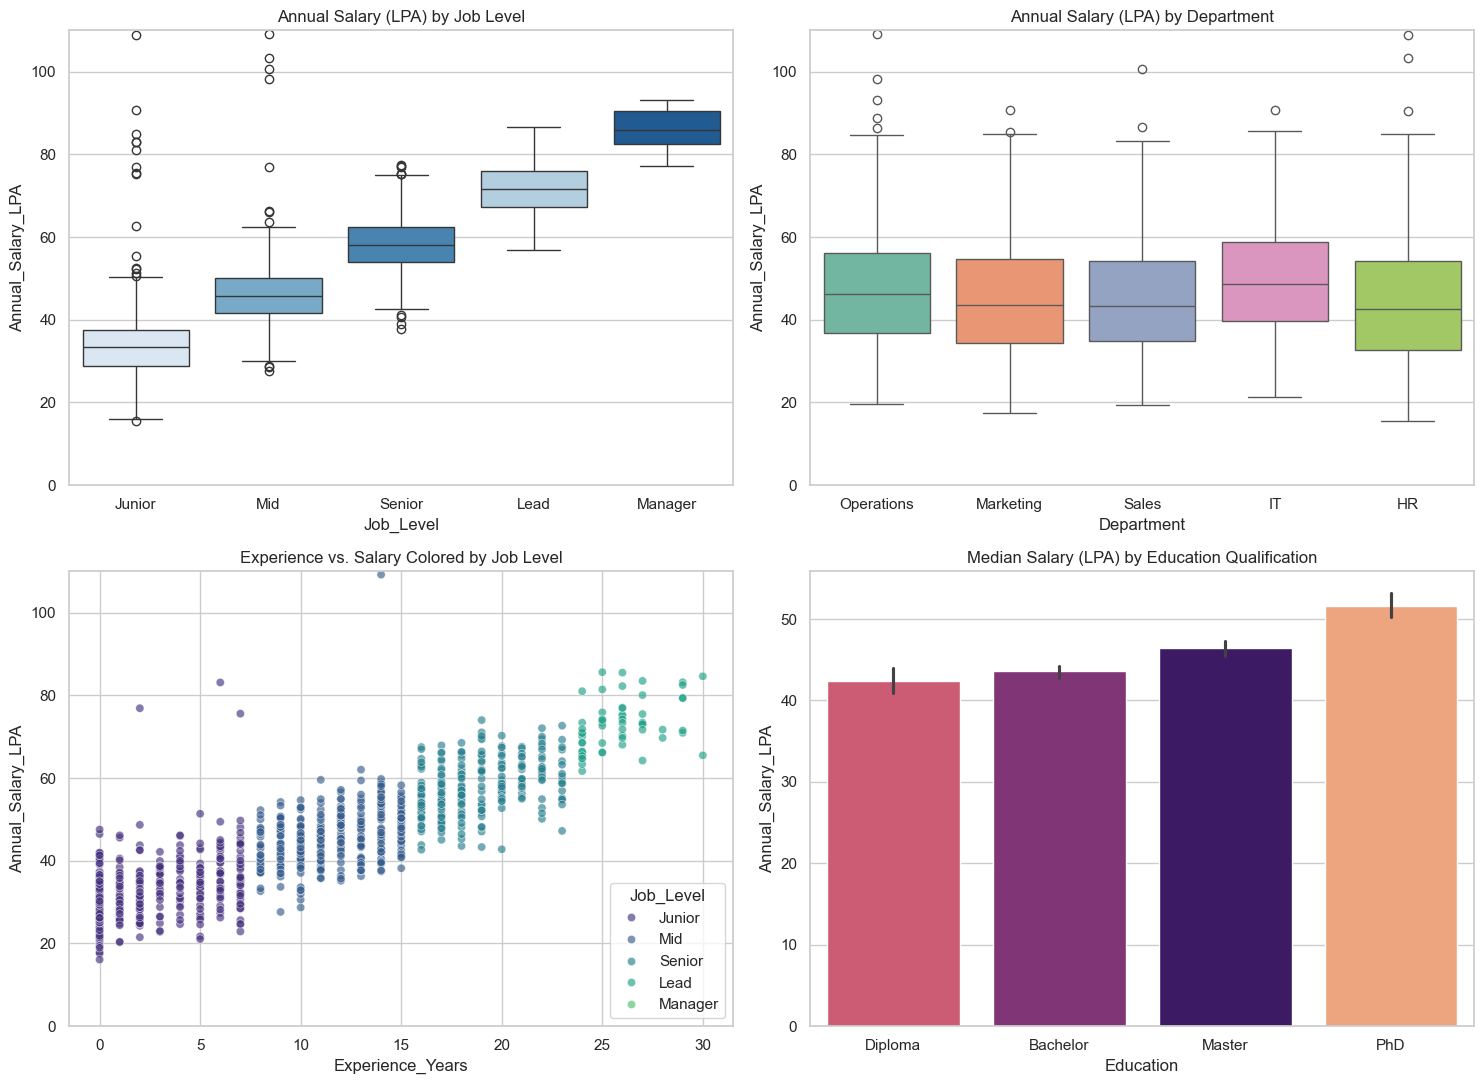

In [4]:
# Visual EDA: Salary distributions across Job Levels, Departments, Experience & Education
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

level_order = ["Junior", "Mid", "Senior", "Lead", "Manager"]
sns.boxplot(
    data=df, x="Job_Level", y="Annual_Salary_LPA",
    hue="Job_Level", order=level_order, palette="Blues", legend=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Annual Salary (LPA) by Job Level")
axes[0, 0].set_ylim(0, 110)

sns.boxplot(
    data=df, x="Department", y="Annual_Salary_LPA",
    hue="Department", palette="Set2", legend=False, ax=axes[0, 1]
)
axes[0, 1].set_title("Annual Salary (LPA) by Department")
axes[0, 1].set_ylim(0, 110)

sns.scatterplot(
    data=df.sample(1000, random_state=42), x="Experience_Years", y="Annual_Salary_LPA",
    hue="Job_Level", hue_order=level_order, alpha=0.65, ax=axes[1, 0]
)
axes[1, 0].set_title("Experience vs. Salary Colored by Job Level")
axes[1, 0].set_ylim(0, 110)

edu_order = ["Diploma", "Bachelor", "Master", "PhD"]
sns.barplot(
    data=df, x="Education", y="Annual_Salary_LPA",
    hue="Education", order=edu_order, estimator=np.median, palette="magma", legend=False, ax=axes[1, 1]
)
axes[1, 1].set_title("Median Salary (LPA) by Education Qualification")

plt.tight_layout()
plt.show()

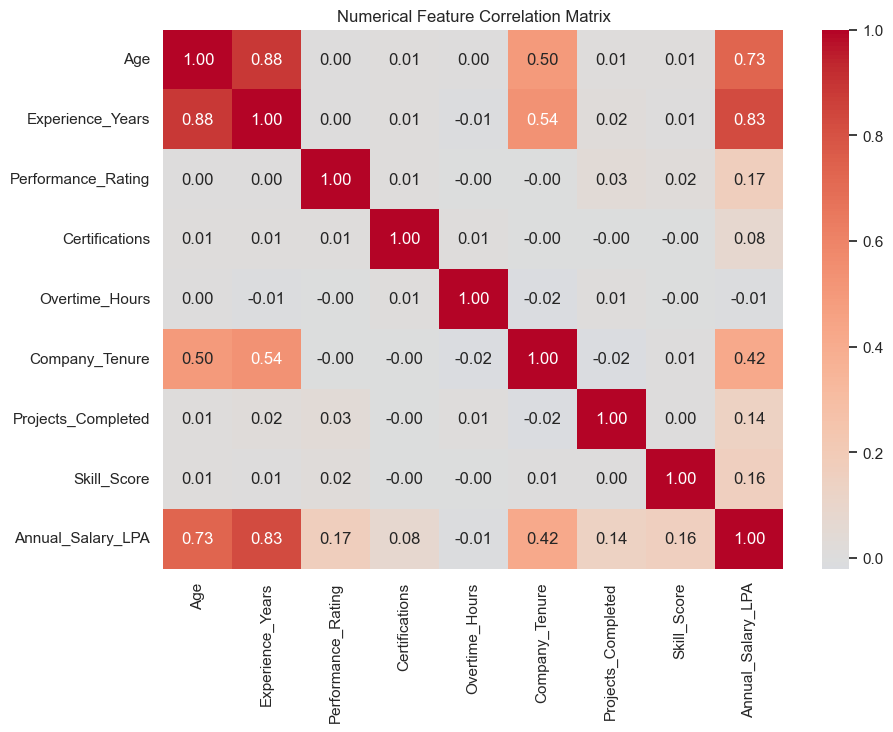

In [5]:
# Correlation Heatmap
plt.figure(figsize=(10, 7))
corr = df.drop(columns=["Employee_ID"]).select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation Matrix")
plt.show()

## 3. Data Cleaning & Feature Engineering Pipeline
Key preprocessing steps built cleanly into a serializable Scikit-Learn `Pipeline`:
1. Drop identifier column `Employee_ID`.
2. Sanitize out-of-range `Age` values (`< 18` or `> 65` set to `NaN` for median imputation).
3. Impute missing values (`Age`: 60, `Experience_Years`: 60, `Skill_Score`: 60) via median imputation and apply `StandardScaler`.
4. One-hot encode categorical attributes (`Gender`, `Education`, `Department`, `Job_Level`, `Remote_Work`, `City`).

In [6]:
df_clean = df.drop(columns=["Employee_ID"]).copy()
df_clean.loc[(df_clean["Age"] < 18) | (df_clean["Age"] > 65), "Age"] = np.nan

X = df_clean.drop(columns=["Annual_Salary_LPA"])
y = df_clean["Annual_Salary_LPA"]

numeric_features = [
    "Age", "Experience_Years", "Performance_Rating", "Certifications",
    "Overtime_Hours", "Company_Tenure", "Projects_Completed", "Skill_Score"
]
categorical_features = [
    "Gender", "Education", "Department", "Job_Level", "Remote_Work", "City"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

Train samples: 4016 | Test samples: 1004


## 4. Multi-Model Training & Outlier-Aware Evaluation

In [7]:
models = {
    "Huber Regressor (Outlier-Robust)": HuberRegressor(max_iter=1500, epsilon=1.35),
    "Ridge Regression": Ridge(alpha=1.0),
    "Linear Regression": LinearRegression(),
    "Gradient Boosting (Huber Loss)": GradientBoostingRegressor(loss="huber", n_estimators=250, learning_rate=0.06, max_depth=4, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42)
}

results = []
trained_pipes = {}
normal_mask = y_test <= 100  # Standard compensation band (excludes 18 extreme outliers)

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe

    preds = pipe.predict(X_test)
    cv_mae = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()

    results.append({
        "Model": name,
        "Standard Band R2 (<=100 LPA)": r2_score(y_test[normal_mask], preds[normal_mask]),
        "Standard Band MAE (LPA)": mean_absolute_error(y_test[normal_mask], preds[normal_mask]),
        "Overall Median AE (LPA)": median_absolute_error(y_test, preds),
        "Overall MAE (LPA)": mean_absolute_error(y_test, preds),
        "5-Fold CV MAE": cv_mae
    })

results_df = pd.DataFrame(results).sort_values(by="Standard Band MAE (LPA)")
display(results_df.style.format({col: "{:.4f}" for col in results_df.columns if col != "Model"}))

,Model,Standard Band R2 (<=100 LPA),Standard Band MAE (LPA),Overall Median AE (LPA),Overall MAE (LPA),5-Fold CV MAE
0,Huber Regressor (Outlier-Robust),0.9079,2.7126,2.2272,3.0818,2.7783
1,Ridge Regression,0.9067,2.7515,2.2707,3.1184,2.8226
2,Linear Regression,0.9067,2.7533,2.2671,3.1202,2.8214
3,Gradient Boosting (Huber Loss),0.9037,2.8337,2.4057,3.1998,2.9689
4,Random Forest Regressor,0.8572,3.4332,2.7752,3.7963,3.5788


## 5. Diagnostics, Feature Drivers & Prediction Intervals

Selected Production Model: Huber Regressor (Outlier-Robust)


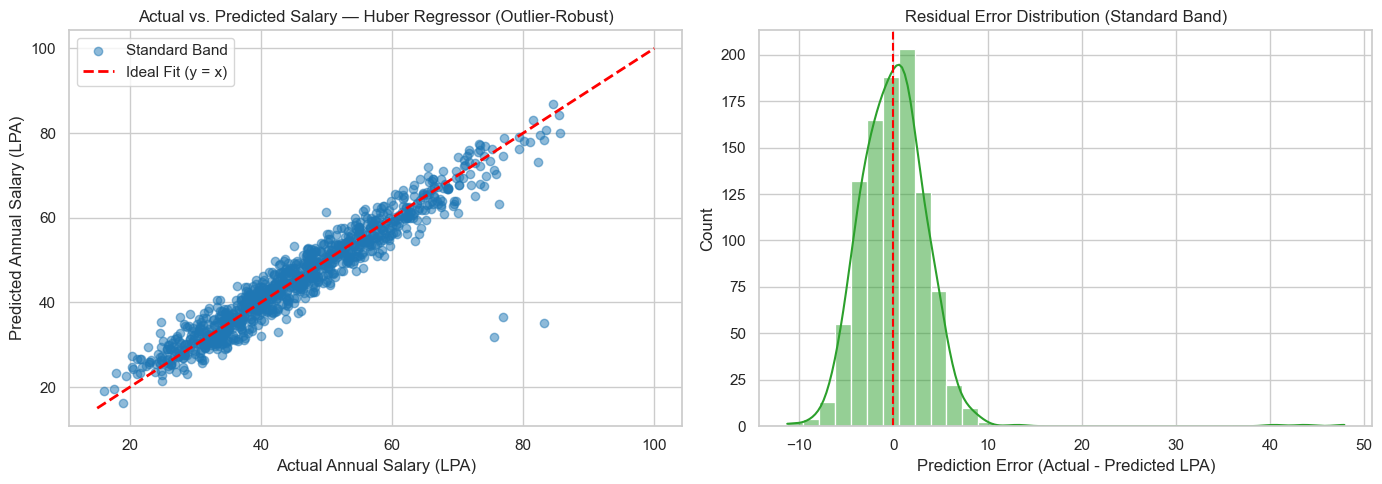

In [8]:
best_model_name = results_df.iloc[0]["Model"]
best_pipe = trained_pipes[best_model_name]
print(f"Selected Production Model: {best_model_name}")

y_pred = best_pipe.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test[normal_mask], y_pred[normal_mask], alpha=0.5, color="#1f77b4", label="Standard Band")
axes[0].plot([15, 100], [15, 100], "r--", lw=2, label="Ideal Fit (y = x)")
axes[0].set_title(f"Actual vs. Predicted Salary — {best_model_name}")
axes[0].set_xlabel("Actual Annual Salary (LPA)")
axes[0].set_ylabel("Predicted Annual Salary (LPA)")
axes[0].legend()

sns.histplot(residuals[normal_mask], bins=35, kde=True, ax=axes[1], color="#2ca02c")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residual Error Distribution (Standard Band)")
axes[1].set_xlabel("Prediction Error (Actual - Predicted LPA)")

plt.tight_layout()
plt.show()

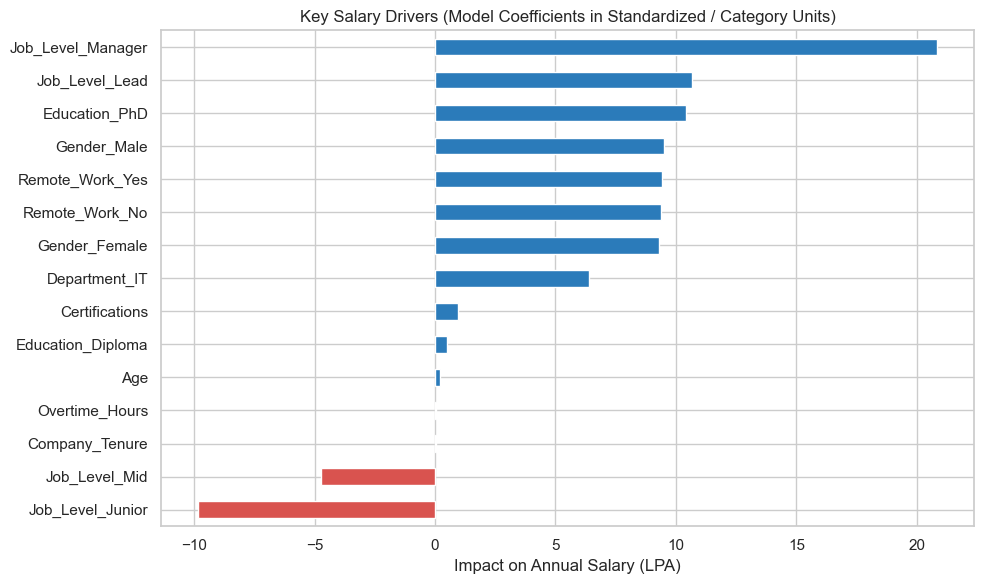

In [9]:
# Extract and visualize linear feature impacts (LPA effect per unit/category)
ohe_names = best_pipe.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features)
all_names = numeric_features + list(ohe_names)
coefs = pd.Series(best_pipe.named_steps["regressor"].coef_, index=all_names).sort_values()

top_effects = pd.concat([coefs.head(7), coefs.tail(8)])
plt.figure(figsize=(10, 6))
colors = ["#d9534f" if v < 0 else "#2b7bba" for v in top_effects.values]
top_effects.plot(kind="barh", color=colors)
plt.title("Key Salary Drivers (Model Coefficients in Standardized / Category Units)")
plt.xlabel("Impact on Annual Salary (LPA)")
plt.tight_layout()
plt.show()

## 6. Train Uncertainty Interval Models & Export Production Bundle

In [10]:
# Train 10th and 90th percentile models for 80% salary confidence intervals
lower_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(loss="quantile", alpha=0.10, n_estimators=200, max_depth=4, random_state=42))
]).fit(X_train, y_train)

upper_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(loss="quantile", alpha=0.90, n_estimators=200, max_depth=4, random_state=42))
]).fit(X_train, y_train)

# Compute peer benchmark percentiles by (Department, Job_Level)
benchmarks = (
    df_clean.groupby(["Department", "Job_Level"])["Annual_Salary_LPA"]
    .agg(
        count="count",
        p25=lambda s: round(float(np.percentile(s, 25)), 2),
        median=lambda s: round(float(np.median(s)), 2),
        p75=lambda s: round(float(np.percentile(s, 75)), 2),
        mean=lambda s: round(float(np.mean(s)), 2)
    )
    .reset_index()
)

artifact = {
    "pipeline": best_pipe,
    "lower_pipeline": lower_pipe,
    "upper_pipeline": upper_pipe,
    "model_name": best_model_name,
    "features": numeric_features + categorical_features,
    "metrics": results_df.iloc[0].to_dict(),
    "all_results": results_df.to_dict(orient="records"),
    "benchmarks": benchmarks.to_dict(orient="records")
}

joblib.dump(artifact, "salary_model.joblib")
print("Exported 'salary_model.joblib' with point estimator, 80% quantile interval models, and peer benchmarks!")

Exported 'salary_model.joblib' with point estimator, 80% quantile interval models, and peer benchmarks!
